# Operational Analysis — Laboratory Turnaround Time (TAT)

**Purpose.** This notebook performs the operational analysis of laboratory turnaround time (TAT)
using the three **already-merged** datasets produced by the cleaning pipeline.

**Data sources** (read-only, in `dataset/cleaned/`):

| File | Grain | Key workflow content |
|---|---|---|
| `item_analysis.csv` | 1 row per order item (test) | item, test, priority, department, `normal_tat_h`, rejection flags |
| `report_analysis.csv` | 1 row per report (item × parameter) | result + `dispatched_at` (report dispatch time) |
| `sample_state_analysis.csv` | 1 row per sample state event (long format) | `state` + `timestamp`: collected → received → processing → verified → reported / rejected |

**Scope of this notebook**

1. Load the three merged datasets and validate shapes and required fields.
2. Normalise datetime columns to timezone-aware UTC — *preserving* columns that are already
   correct and converting only those that arrived as strings/objects.
3. Identify the laboratory workflow timestamps and define TAT stages.
4. Compute TAT in hours, with **collection → final report** as the primary overall TAT.
5. Assemble a clean, analysis-ready TAT dataframe for downstream analysis.
6. Break overall TAT down by **workflow stage** — overall and per department — to locate
   the main contributor to turnaround time.

## 1. Setup

Answers: *what environment, libraries and conventions does this notebook use?*

All paths are resolved from the notebook location so the notebook runs regardless of the
current working directory. The cleaned datasets are **never written back** — this notebook
is read-only with respect to the data layer.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)

# --- Reusable paths (notebook lives in notebook/, data in ../dataset/cleaned/) ---
NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent
DATA_DIR = PROJECT_DIR / "dataset" / "cleaned"

CLEANED_DATASETS = {
    "item_analysis": DATA_DIR / "item_analysis.csv",
    "report_analysis": DATA_DIR / "report_analysis.csv",
    "sample_state_analysis": DATA_DIR / "sample_state_analysis.csv",
}

DATA_DIR

WindowsPath('C:/Users/yusra/Documents/Python/UV/laboratory-data-analysis/src/laboratory_data_analysis/dataset/cleaned')

## 2. Load the merged datasets

Answers: *which files are loaded, and what are their dimensions?*

The datasets are loaded with a single reusable loader. `utf-8-sig` is used because the cleaned
CSV files carry a BOM. No merging or re-cleaning is performed — the merged datasets are used
as-is.

In [2]:
def load_dataset(name: str, path: Path) -> pd.DataFrame:
    """Load one cleaned CSV dataset. utf-8-sig strips the BOM written by the cleaning step."""
    df = pd.read_csv(path, encoding="utf-8-sig")
    print(f"Loaded   : {name}  <-  {path.name}")
    print(f"  path   : {path}")
    print(f"  shape  : {df.shape[0]:,} rows x {df.shape[1]} columns\n")
    return df

datasets = {name: load_dataset(name, path) for name, path in CLEANED_DATASETS.items()}

item_df = datasets["item_analysis"]
report_df = datasets["report_analysis"]
sample_state_df = datasets["sample_state_analysis"]

print("Summary")
for name, df in datasets.items():
    print(f"  {name:<22} rows={df.shape[0]:>7,}  cols={df.shape[1]}")

Loaded   : item_analysis  <-  item_analysis.csv
  path   : C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\dataset\cleaned\item_analysis.csv
  shape  : 72,947 rows x 32 columns



Loaded   : report_analysis  <-  report_analysis.csv
  path   : C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\dataset\cleaned\report_analysis.csv
  shape  : 125,981 rows x 43 columns



Loaded   : sample_state_analysis  <-  sample_state_analysis.csv
  path   : C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\dataset\cleaned\sample_state_analysis.csv
  shape  : 235,558 rows x 19 columns

Summary
  item_analysis          rows= 72,947  cols=32
  report_analysis        rows=125,981  cols=43
  sample_state_analysis  rows=235,558  cols=19


## 3. Validation — required fields for operational analysis

Answers: *do the merged datasets contain every field required for TAT analysis?*

Each dataset is checked against an explicit contract of required columns. The validation is
a hard gate: analysis proceeds only if all required fields are present. Nothing is
re-merged unless this check fails.

In [3]:
REQUIRED_FIELDS = {
    "item_analysis": [
        # keys
        "order_item_id", "order_id", "test_id", "sample_id",
        # context for operational breakdowns
        "department_name", "test_name", "priority", "sample_type",
        # SLA reference
        "normal_tat_h",
        # workflow / quality flags
        "order_created_at", "is_rejected",
    ],
    "report_analysis": [
        # keys
        "report_id", "order_item_id", "parameter_id", "sample_id",
        # report workflow
        "dispatched_at", "order_created_at",
        # result context
        "parameter_name", "value", "unit_x", "flag",
    ],
    "sample_state_analysis": [
        # state log (long format)
        "sample_state_id", "sample_id", "state", "timestamp",
        # linkage + context
        "order_id", "patient_id", "order_created_at", "sample_type", "is_rejected",
    ],
}


def validate_required_fields(name: str, df: pd.DataFrame, required: list[str]) -> bool:
    """Check a dataset for all required fields. Returns True when the contract is satisfied."""
    missing = [c for c in required if c not in df.columns]
    if missing:
        print(f"{name:<24} MISSING: {missing}")
        return False
    print(f"{name:<24} OK  ({len(required)}/{len(required)} required fields present)")
    return True


validation_ok = all(
    validate_required_fields(name, datasets[name], fields)
    for name, fields in REQUIRED_FIELDS.items()
)
assert validation_ok, "Required fields missing -> re-visit the cleaning/merging pipeline."
print("\nAll datasets contain the fields required for operational analysis.")

item_analysis            OK  (11/11 required fields present)
report_analysis          OK  (10/10 required fields present)
sample_state_analysis    OK  (9/9 required fields present)

All datasets contain the fields required for operational analysis.


## 4. DateTime normalisation — preserve UTC, convert only when needed

Answers: *are the datetime columns timezone-aware UTC after loading, and which columns
needed conversion?*

The cleaned datasets store timestamps as ISO strings such as
`2025-06-17 23:22:01+00:00`. When loaded through `read_csv` they arrive as plain objects.
The rule applied here:

- **already a timezone-aware UTC datetime dtype** → left untouched (preserved);
- **object / string / naive datetime** → converted once with `pd.to_datetime(..., utc=True)`
  so the dtype becomes `datetime64[ns, UTC]`.

All project analysis to date uses UTC, so UTC is preserved consistently. The original files
are never modified.

In [4]:
# Datetime columns relevant to the operational analysis, per dataset.
DATETIME_COLUMNS = {
    "item_analysis": ["order_created_at"],
    "report_analysis": ["order_created_at", "dispatched_at"],
    "sample_state_analysis": ["timestamp", "order_created_at"],
}


def ensure_utc_datetime(df: pd.DataFrame, columns: list[str], name: str) -> pd.DataFrame:
    """Return a copy of `df` where every column in `columns` is timezone-aware UTC.

    Columns that already carry a tz-aware UTC dtype are preserved as-is; everything
    else (strings/objects/naive) is converted once via pd.to_datetime(..., utc=True).
    Invalid/missing values become NaT instead of raising.
    """
    out = df.copy()
    for col in columns:
        dtype = out[col].dtype
        if isinstance(dtype, pd.DatetimeTZDtype):
            if str(dtype.tz) == "UTC":
                action = "preserved (already tz-aware UTC)"
            else:  # tz-aware but not UTC -> localise correctly to UTC
                out[col] = out[col].dt.tz_convert("UTC")
                action = "tz_convert('UTC')"
        else:
            out[col] = pd.to_datetime(out[col], utc=True, errors="coerce")
            action = "converted from object -> to_datetime(utc=True)"
        print(f"  {name:<22} {col:<18} before={str(dtype):<22} after={out[col].dtype}  [{action}]")
    return out


for name, columns in DATETIME_COLUMNS.items():
    datasets[name] = ensure_utc_datetime(datasets[name], columns, name)

item_df = datasets["item_analysis"]
report_df = datasets["report_analysis"]
sample_state_df = datasets["sample_state_analysis"]

print("\nAudit: first raw string vs stored datetime value")
print(f"  sample_state timestamp : {sample_state_df['timestamp'].iloc[0]}  (dtype {sample_state_df['timestamp'].dtype})")
print(f"  report dispatched_at   : {report_df['dispatched_at'].iloc[0]}  (dtype {report_df['dispatched_at'].dtype})")

  item_analysis          order_created_at   before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]
  report_analysis        order_created_at   before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]


  report_analysis        dispatched_at      before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]


  sample_state_analysis  timestamp          before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]
  sample_state_analysis  order_created_at   before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]

Audit: first raw string vs stored datetime value
  sample_state timestamp : 2025-06-17 23:54:17+00:00  (dtype datetime64[us, UTC])
  report dispatched_at   : 2025-06-18 07:10:29+00:00  (dtype datetime64[us, UTC])


## 5. Identify TAT fields — the laboratory workflow timeline

Answers: *which timestamps represent the laboratory workflow, and what does each stage mean?*

`sample_state_analysis` is an event log: each row is one state change of a sample with a
`timestamp`. The distinct states below define the workflow stages. Together with
`order_created_at` (order placement, available in all three datasets) and `dispatched_at`
(report dispatch, in `report_analysis`) they give the complete TAT chain:

In [5]:
# What states actually exist in the workflow log?
state_counts = sample_state_df["state"].value_counts()
display(state_counts.to_frame("events"))

print("Distinct workflow stages (in workflow order):")
for stage in ["collected", "received", "processing", "verified", "reported", "rejected"]:
    n = state_counts.get(stage, 0)
    print(f"  {stage:<11} {n:>7,} events")

,events
state,
collected,49260
received,48873
processing,48873
verified,45655
reported,42510
rejected,387


Distinct workflow stages (in workflow order):
  collected    49,260 events
  received     48,873 events
  processing   48,873 events
  verified     45,655 events
  reported     42,510 events
  rejected        387 events


### Workflow timestamp map

| TAT stage | Timestamp | Source | Meaning |
|---|---|---|---|
| Order placed | `order_created_at` | item / report / sample_state | clinician ordered the test |
| **Sample collection** | `timestamp` where `state == 'collected'` | sample_state_analysis | sample drawn from patient |
| **Sample received** | `timestamp` where `state == 'received'` | sample_state_analysis | lab reception logged the sample |
| Processing start | `timestamp` where `state == 'processing'` | sample_state_analysis | sample entered analysis workflow |
| **Verified** | `timestamp` where `state == 'verified'` | sample_state_analysis | result verified in the lab |
| **Final report** | `timestamp` where `state == 'reported'` | sample_state_analysis | report released (primary TAT endpoint) |
| Report dispatched | `dispatched_at` | report_analysis | per-parameter report dispatch (post-analytical cross-check) |

**TAT definitions used in this notebook (all in hours)**

| Interval | Formula | Interpretation |
|---|---|---|
| Pre-analytical TAT | collected → received | logistics between ward and lab |
| Analytical TAT | received → verified | bench processing and verification |
| Post-analytical TAT | verified → reported | validation-to-release delay |
| **Overall TAT (primary)** | **collected → final report** | end-to-end turnaround users experience |

The primary overall TAT uses **sample collection → final report**, as required, and is only
defined for samples that actually reached the `reported` state (rejected samples are
excluded from TAT but counted separately).

## 6. Build the sample-level TAT dataframe

Answers: *how do the event-log timestamps become one row per sample with one column per workflow stage?*

The long-format state log is pivoted to wide form (`sample_id` × stage), then enriched with
sample attributes from the item dataset (`department_name`, `priority`, `sample_type`,
rejection flag) and the **strictest** SLA target applicable to the sample
(`min(normal_tat_h)` across all tests on that sample — the most demanding test defines the
deadline the lab must meet).

> **Note on `normal_tat_h` semantics**: the SLA comparison assumes `normal_tat_h` is the
target TAT (in hours) a test should meet. The breach rates this produces should be
sanity-checked against lab policy before drawing operational conclusions.

In [6]:
def build_sample_tat(item_df: pd.DataFrame, sample_state_df: pd.DataFrame) -> pd.DataFrame:
    """Pivot the sample state log to one row per sample and attach item context.

    Returns a frame keyed by sample_id with:
      - one datetime column per workflow state (collected/received/processing/verified/reported)
      - context: department_name, priority, sample_type, is_rejected
      - sla_target_h: strictest normal_tat_h among all tests on the sample
    """
    stage_times = sample_state_df.pivot_table(
        index="sample_id", columns="state", values="timestamp", aggfunc="first"
    )
    stage_times.columns = [f"{col}_at" for col in stage_times.columns]

    # One attributes row per sample: first occurrence of shared attributes,
    # min() for the SLA target so the strictest test standard applies.
    attrs = (
        item_df.sort_values("order_item_id")
        .groupby("sample_id")
        .agg(
            department_name=("department_name", "first"),
            priority=("priority", "first"),
            sample_type=("sample_type", "first"),
            is_rejected=("is_rejected", "max"),          # any test rejected -> sample-level flag
            n_tests_on_sample=("order_item_id", "count"),
            sla_target_h=("normal_tat_h", "min"),
        )
    )
    sample_tat = attrs.join(stage_times, how="left")
    return sample_tat.reset_index()


sample_tat = build_sample_tat(item_df, sample_state_df)

print(f"sample_tat: {sample_tat.shape[0]:,} samples x {sample_tat.shape[1]} columns\n")
print("Workflow completeness per stage:")
for col in ["collected_at", "received_at", "processing_at", "verified_at", "reported_at"]:
    n = sample_tat[col].notna().sum()
    print(f"  {col:<16} {n:>7,} ({n / len(sample_tat):>6.1%})")
print(f"  rejected samples : {sample_tat['is_rejected'].sum():>7,}")

sample_tat: 49,260 samples x 13 columns

Workflow completeness per stage:
  collected_at      49,260 (100.0%)
  received_at       48,873 ( 99.2%)
  processing_at     48,873 ( 99.2%)
  verified_at       45,655 ( 92.7%)
  reported_at       42,510 ( 86.3%)
  rejected samples :     387


## 7. Compute TAT (hours) — primary overall TAT + stage intervals

Answers: *how long does the laboratory take at each workflow stage, and end to end?*

- All durations are differences of timezone-aware UTC timestamps, expressed in **hours**.
- **`tat_total_h` = collected → reported** is the primary overall TAT.
- Impossible (negative) intervals are set to `NaN` and reported as data-quality counts
  rather than silently correcting timestamps.
- Rejected samples never reach `reported`, so they fall out of the primary TAT scope
  automatically (their events remain in the source log).

In [7]:
def add_tat_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Add TAT intervals, in hours, derived from the workflow timestamps."""
    out = df.copy()
    hours = lambda start, end: (out[end] - out[start]).dt.total_seconds() / 3600

    out["pre_analytical_tat_h"] = hours("collected_at", "received_at")     # collection -> reception
    out["analytical_tat_h"] = hours("received_at", "verified_at")          # reception  -> verification
    out["post_analytical_tat_h"] = hours("verified_at", "reported_at")     # verification -> release
    out["tat_total_h"] = hours("collected_at", "reported_at")              # PRIMARY: collection -> final report

    # Data quality: negative intervals are logically impossible -> invalidate, do not reuse.
    interval_cols = ["pre_analytical_tat_h", "analytical_tat_h", "post_analytical_tat_h", "tat_total_h"]
    for col in interval_cols:
        bad = (out[col] < 0).sum()
        if bad:
            print(f"  invalid: {bad:,} negative values in {col} -> set to NaN")
        out.loc[out[col] < 0, col] = np.nan

    # SLA compliance against the strictest applicable normal TAT.
    in_scope = out["tat_total_h"].notna()
    out["sla_breach"] = np.where(in_scope, out["tat_total_h"] > out["sla_target_h"], np.nan)
    return out


sample_tat = add_tat_columns(sample_tat)

scope = sample_tat["tat_total_h"].notna().sum()
print(f"Samples with primary TAT (collected -> reported): {scope:,} / {len(sample_tat):,} "
      f"({scope / len(sample_tat):.1%} of all samples)")
print(f"Excluded: rejected/no-report samples = {len(sample_tat) - scope:,}, "
      f"SLA breaches flagged on {int(sample_tat['sla_breach'].sum()):,} in-scope samples")

Samples with primary TAT (collected -> reported): 42,510 / 49,260 (86.3% of all samples)
Excluded: rejected/no-report samples = 6,750, SLA breaches flagged on 41,717 in-scope samples


## 8. Clean analysis dataframe — the TAT analysis table

Answers: *what does the final, analysis-ready TAT dataframe look like, and what does it say at a glance?*

`tat_analysis_df` keeps exactly the fields needed for TAT analysis, in tidy order:
identity → context → workflow timestamps → TAT intervals → SLA flag. It is the single
reusable artefact this notebook hands to every downstream operational analysis (charts,
department deep-dives, dashboards).

In [8]:
FINAL_COLUMNS = [
    # identity
    "sample_id",
    # context
    "department_name", "priority", "sample_type", "n_tests_on_sample", "is_rejected",
    # SLA reference
    "sla_target_h",
    # workflow timestamps (UTC)
    "collected_at", "received_at", "processing_at", "verified_at", "reported_at",
    # TAT intervals, hours
    "pre_analytical_tat_h", "analytical_tat_h", "post_analytical_tat_h", "tat_total_h",
    # outcome flag
    "sla_breach",
]

tat_analysis_df = (
    sample_tat.loc[:, FINAL_COLUMNS]
    .sort_values("sample_id")
    .reset_index(drop=True)
)

display(tat_analysis_df.head())
print(f"\ntat_analysis_df: {tat_analysis_df.shape[0]:,} rows x {tat_analysis_df.shape[1]} columns")

,sample_id,department_name,priority,sample_type,n_tests_on_sample,is_rejected,sla_target_h,collected_at,received_at,processing_at,verified_at,reported_at,pre_analytical_tat_h,analytical_tat_h,post_analytical_tat_h,tat_total_h,sla_breach
0,1,Immunology,stat,serum,3,False,3,2025-06-17 23:54:17+00:00,2025-06-18 02:07:03+00:00,2025-06-18 03:45:54+00:00,2025-06-18 05:37:48+00:00,2025-06-18 07:10:29+00:00,2.21,3.51,1.54,7.27,1.00
1,2,Molecular Diagnostics,routine,blood,1,False,6,2025-06-18 00:21:11+00:00,2025-06-18 07:02:38+00:00,2025-06-18 08:14:07+00:00,2025-06-18 19:07:38+00:00,2025-06-18 19:42:09+00:00,6.69,12.08,0.58,19.35,1.00
2,3,Molecular Diagnostics,routine,blood,3,False,2,2025-07-06 12:06:59+00:00,2025-07-06 18:34:04+00:00,2025-07-06 20:47:50+00:00,2025-07-07 07:03:46+00:00,2025-07-07 08:54:34+00:00,6.45,12.49,1.85,20.79,1.00
3,4,Immunology,routine,serum,2,False,2,2025-07-06 12:32:30+00:00,2025-07-06 18:43:06+00:00,2025-07-06 22:28:25+00:00,NaT,NaT,6.18,NaN,NaN,NaN,NaN
4,5,Histopathology,routine,pleural fluid,2,False,6,2025-02-17 10:41:04+00:00,2025-02-17 12:33:39+00:00,2025-02-17 16:02:26+00:00,2025-02-17 23:51:14+00:00,2025-02-18 01:33:43+00:00,1.88,11.29,1.71,14.88,1.00



tat_analysis_df: 49,260 rows x 17 columns


### First read of the numbers

Quick operational overview of the primary TAT, split by order priority — the standard
operational lens in a clinical laboratory.

In [9]:
in_scope = tat_analysis_df[tat_analysis_df["tat_total_h"].notna()]

overview = (
    in_scope.groupby("priority")["tat_total_h"]
    .agg(samples="count", median_h="median", mean_h="mean", p90_h=lambda s: s.quantile(0.9))
    .assign(breach_rate=lambda t: (
        in_scope.groupby("priority")["sla_breach"].mean().reindex(t.index)))
)
display(overview)

overall_stage = in_scope[["pre_analytical_tat_h", "analytical_tat_h",
                          "post_analytical_tat_h", "tat_total_h"]].median()
print("\nMedian hours per workflow stage (all priorities):")
for name, value in overall_stage.items():
    print(f"  {name:<20} {value:>6.2f}")


,samples,median_h,mean_h,p90_h,breach_rate
priority,,,,,
emergency,6056,15.49,15.51,20.84,0.98
routine,32102,15.53,15.52,20.87,0.98
stat,4352,15.55,15.54,20.89,0.99



Median hours per workflow stage (all priorities):
  pre_analytical_tat_h   4.50
  analytical_tat_h       8.79
  post_analytical_tat_h   2.24
  tat_total_h           15.53


## 9. Sample Workflow Stage Analysis — where is the time spent?

**Purpose.** Identify *where* time is spent inside the laboratory workflow and determine
**which workflow stage is the main contributor to overall turnaround time** (§7 measured
end-to-end TAT; this section decomposes it).

**Workflow analysed:** `Collection → Received → Processing → Verified → Reported`

**Questions answered**

1. Overall: what are the elapsed hours for each transition, and which stage dominates?
2. Department level: which department has the **longest overall TAT**?
3. Department level: for each department, **which stage contributes the most delay**?

**Reuse note:** the workflow timestamps and `pre_analytical_tat_h` / `post_analytical_tat_h`
/ overall TAT already exist in `tat_analysis_df` (§7–§8). Only the two transitions not
previously derived — *Received → Processing* and *Processing → Verified* — are computed
here, on top of that existing frame. Nothing is recalculated from the raw datasets.

In [10]:
STAGE_TRANSITIONS = [
    # (column, start timestamp, end timestamp, transition label, short label)
    ("pre_analytical_tat_h",      "collected_at",   "received_at",   "Collection → Received",  "COLL → REC"),
    ("received_processing_tat_h", "received_at",    "processing_at", "Received → Processing",  "REC → PROC"),
    ("processing_verified_tat_h", "processing_at",  "verified_at",   "Processing → Verified",  "PROC → VER"),
    ("post_analytical_tat_h",     "verified_at",    "reported_at",   "Verified → Reported",    "VER → REP"),
    ("tat_total_h",               "collected_at",   "reported_at",   "Collection → Reported",  "Overall TAT"),
]
LAYER_TRANSITIONS = STAGE_TRANSITIONS[:-1]            # the four building blocks of overall TAT
TRANSITION_LABELS = {t[0]: t[3] for t in LAYER_TRANSITIONS}
SHORT_LABELS = {t[0]: t[4] for t in LAYER_TRANSITIONS}
layer_cols = [t[0] for t in LAYER_TRANSITIONS]


def add_stage_transitions(tat_df: pd.DataFrame) -> pd.DataFrame:
    """Extend the existing TAT dataframe with the workflow stage intervals still missing (hours).

    Sections 7-8 already produced pre/analytical/post/total intervals; only transitions
    not present are derived here, and negative results are invalidated to NaN.
    """
    out = tat_df.copy()
    for col, start, end, _, _ in STAGE_TRANSITIONS:
        if col not in out.columns:
            hours = (out[end] - out[start]).dt.total_seconds() / 3600
            out[col] = hours.where(hours >= 0)   # logically impossible intervals -> NaN
    return out


stage_analysis_df = add_stage_transitions(tat_analysis_df)

print("Stage intervals available (hours):\n")
for col, start, end, label, short in STAGE_TRANSITIONS:
    n = int(stage_analysis_df[col].notna().sum())
    print(f"  {label:<24} ({short:<10}) valid pairs: {n:>7,}  ({n / len(stage_analysis_df):>6.1%})")

Stage intervals available (hours):

  Collection → Received    (COLL → REC) valid pairs:  48,873  ( 99.2%)
  Received → Processing    (REC → PROC) valid pairs:  48,873  ( 99.2%)
  Processing → Verified    (PROC → VER) valid pairs:  45,655  ( 92.7%)
  Verified → Reported      (VER → REP ) valid pairs:  42,510  ( 86.3%)
  Collection → Reported    (Overall TAT) valid pairs:  42,510  ( 86.3%)


### 9.1 Overall stage-wise time differences

Answers: *where does the laboratory spend its time, overall?*

For each transition: the number of complete timestamp pairs, the **median** and **mean**
elapsed hours, and — based only on samples that completed *all four transitions* — each
stage's **share of overall TAT**. Shares use the mean on complete cases because stage
medians are not additive (median of a sum ≠ sum of medians).

In [11]:
def summarise_stage(stage_col: str) -> pd.Series:
    """Count / median / mean (hours) for one workflow transition."""
    s = stage_analysis_df[stage_col].dropna()
    return pd.Series({"n": int(s.size), "median_h": s.median(), "mean_h": s.mean()})


overall_stage_summary = pd.DataFrame(
    {TRANSITION_LABELS[col]: summarise_stage(col) for col, *_ in LAYER_TRANSITIONS}
).T

# Share of overall TAT — unbiased only when all four transitions are complete.
complete = stage_analysis_df[layer_cols].dropna()
stage_means = complete.mean()
shares = stage_means / stage_means.sum()

share_by_label = shares.set_axis([TRANSITION_LABELS[c] for c in layer_cols])
display(overall_stage_summary.assign(share_of_overall_pct=share_by_label))

dominant = shares.idxmax()
print(f"\nMain contributor to overall TAT: '{TRANSITION_LABELS[dominant]}' — "
      f"{shares[dominant]:.1%} of mean overall duration "
      f"({stage_means[dominant]:.1f} of {stage_means.sum():.1f} mean hours).")
print(f"Slowest stage by median: {overall_stage_summary['median_h'].idxmax()} "
      f"at {overall_stage_summary['median_h'].max():.1f} h.")

,n,median_h,mean_h,share_of_overall_pct
Collection → Received,"48,873.00",4.51,4.51,0.29
Received → Processing,"48,873.00",2.26,2.25,0.15
Processing → Verified,"45,655.00",6.50,6.52,0.42
Verified → Reported,"42,510.00",2.24,2.24,0.14



Main contributor to overall TAT: 'Processing → Verified' — 42.0% of mean overall duration (6.5 of 15.5 mean hours).
Slowest stage by median: Processing → Verified at 6.5 h.


### 9.2 Department-level stage table

Answers: *which department has the longest overall TAT, and which stage is each department's biggest delay?*

Shaped exactly as requested — **rows = departments**, **columns = the four workflow
transitions**, **values = duration in hours** (median). `overall_tat_h` is appended so
departments are ranked by end-to-end TAT, and `largest_delay_stage` names each department's
heaviest transition, making the bottleneck readable at a glance.

In [12]:
def build_department_stage_table(df: pd.DataFrame) -> pd.DataFrame:
    """Department x stage matrix of median durations (hours), ranked by overall TAT.

    Columns:
      n_samples           rows behind each department's numbers
      overall_tat_h       median collection -> reported TAT (ranking metric)
      <4 stage columns>   median hours per workflow transition
      largest_delay_stage name of the transition with the highest median in that department
    """
    dept_stats = df.groupby("department_name").agg(
        n_samples=("sample_id", "size"),
        overall_tat_h=("tat_total_h", "median"),
    )
    table = dept_stats.join(df.groupby("department_name")[layer_cols].median())

    # Dominant stage per department (rank comparison); NaN only if no stage is measurable.
    dominant_stage = (
        table.loc[table[layer_cols].notna().any(axis=1), layer_cols]
        .idxmax(axis=1)
        .map(TRANSITION_LABELS)
        .reindex(table.index)
    )
    table["largest_delay_stage"] = dominant_stage
    return table.sort_values("overall_tat_h", ascending=False)


dept_stage_table = build_department_stage_table(stage_analysis_df)
display(dept_stage_table)

,n_samples,overall_tat_h,pre_analytical_tat_h,received_processing_tat_h,processing_verified_tat_h,post_analytical_tat_h,largest_delay_stage
department_name,,,,,,,
Hematology,5883,15.58,4.49,2.24,6.53,2.21,Processing → Verified
Histopathology,3660,15.58,4.50,2.26,6.52,2.28,Processing → Verified
Microbiology,4211,15.58,4.48,2.25,6.46,2.28,Processing → Verified
Serology,6674,15.55,4.56,2.28,6.48,2.25,Processing → Verified
Immunology,4177,15.52,4.54,2.27,6.44,2.30,Processing → Verified
Endocrinology,5233,15.51,4.47,2.24,6.52,2.25,Processing → Verified
Clinical Chemistry,4808,15.51,4.46,2.30,6.54,2.22,Processing → Verified
Molecular Diagnostics,5221,15.50,4.55,2.26,6.50,2.24,Processing → Verified
Cytology,2964,15.49,4.47,2.26,6.54,2.25,Processing → Verified


### 9.3 Visual readings of the department table

Answers: *how large are the inter-department differences, and how does each department's TAT decompose by stage?*

- **Figure 1 — Overall TAT by department** (requested bar chart): median end-to-end hours,
  ranked, annotated with the row count behind each bar.
- **Figure 2 — Stage composition**: stacked bars (mean hours on complete cases, so segments
  sum to the bar total) in the same ranking — the *thickest segment* of each bar is that
  department's dominant delay.
- **Figure 3 — Stage heatmap**: the department × stage median matrix as heat, making the
  largest delay cell per row pop out.

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

STAGE_COLORS = ["#bdd7e7", "#6baed6", "#3182bd", "#08519c"]  # light -> dark, Collection -> Reported
sns.set_theme(style="whitegrid", context="notebook")

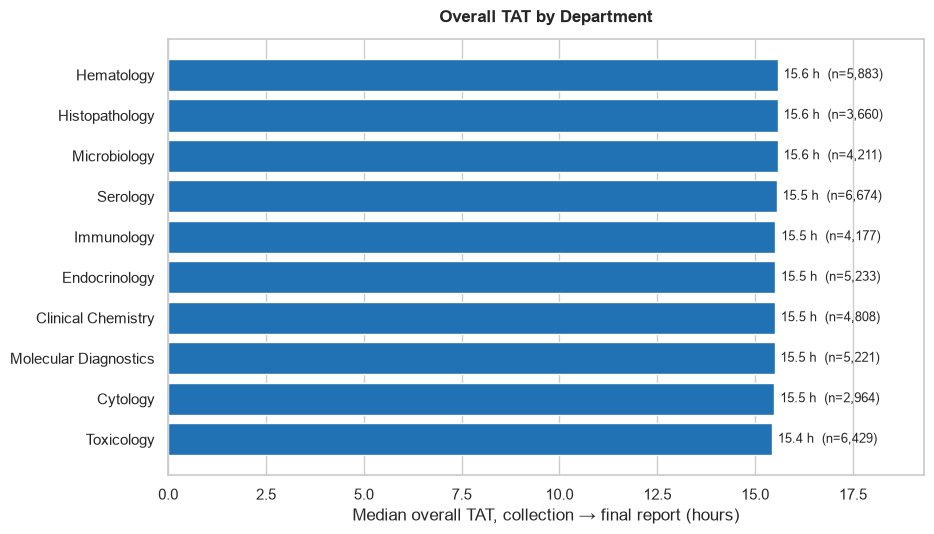

In [14]:
# Figure 1 - Overall TAT by department (requested bar chart)
ranked = dept_stage_table  # already ranked by overall_tat_h (desc)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.barh(ranked.index, ranked["overall_tat_h"], color="#2171b5", edgecolor="white")
ax.invert_yaxis()  # slowest department on top
ax.set_xlabel("Median overall TAT, collection → final report (hours)")
ax.set_title("Overall TAT by Department", fontweight="bold", pad=12)

for bar, dept in zip(bars, ranked.index):
    n = int(ranked.at[dept, "n_samples"])
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f} h  (n={n:,})", va="center", fontsize=9)

ax.set_xlim(0, ranked["overall_tat_h"].max() * 1.24)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

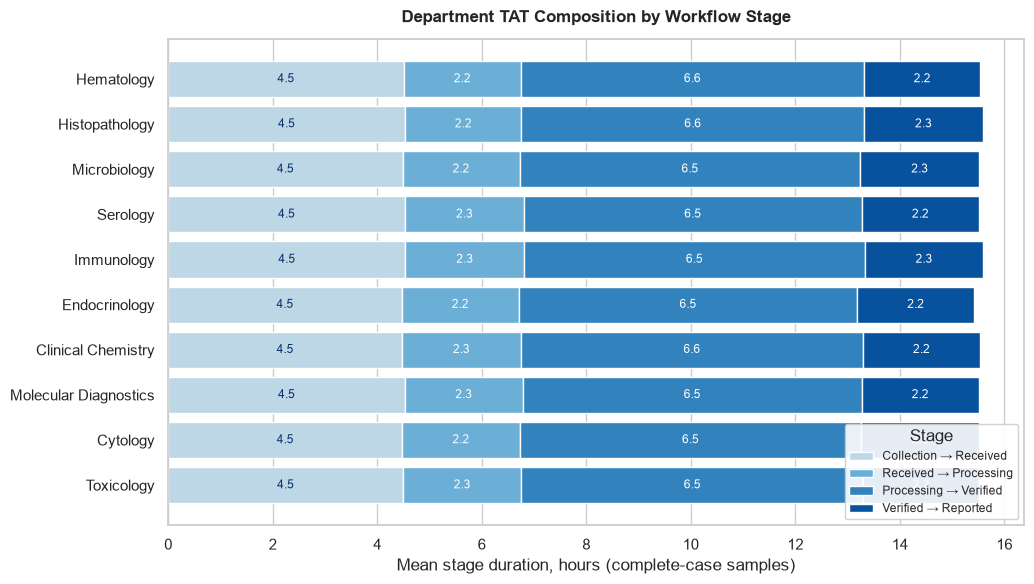

In [15]:
# Figure 2 - Stage composition by department (stacked bars, complete cases)
layer_means = (
    stage_analysis_df[stage_analysis_df[layer_cols].notna().all(axis=1)]
    .groupby("department_name")[layer_cols]
    .mean()
    .reindex(ranked.index)
)

fig, ax = plt.subplots(figsize=(10.5, 6))
left = pd.Series(0.0, index=layer_means.index)
for col, colour in zip(layer_cols, STAGE_COLORS):
    segment = layer_means[col]
    ax.barh(segment.index, segment.values, left=left, color=colour, edgecolor="white",
            label=TRANSITION_LABELS[col])
    for y, (w, start) in enumerate(zip(segment.values, left)):
        if w >= 1.5:
            ax.text(start + w / 2, y, f"{w:.1f}", ha="center", va="center", fontsize=8.5,
                    color="white" if col in (layer_cols[1], layer_cols[2], layer_cols[3]) else "#08306b")
    left = left + segment.fillna(0)

ax.invert_yaxis()  # match Figure 1 ranking
ax.set_xlabel("Mean stage duration, hours (complete-case samples)")
ax.set_title("Department TAT Composition by Workflow Stage", fontweight="bold", pad=12)
ax.legend(title="Stage", loc="lower right", fontsize=8.5, framealpha=0.9)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

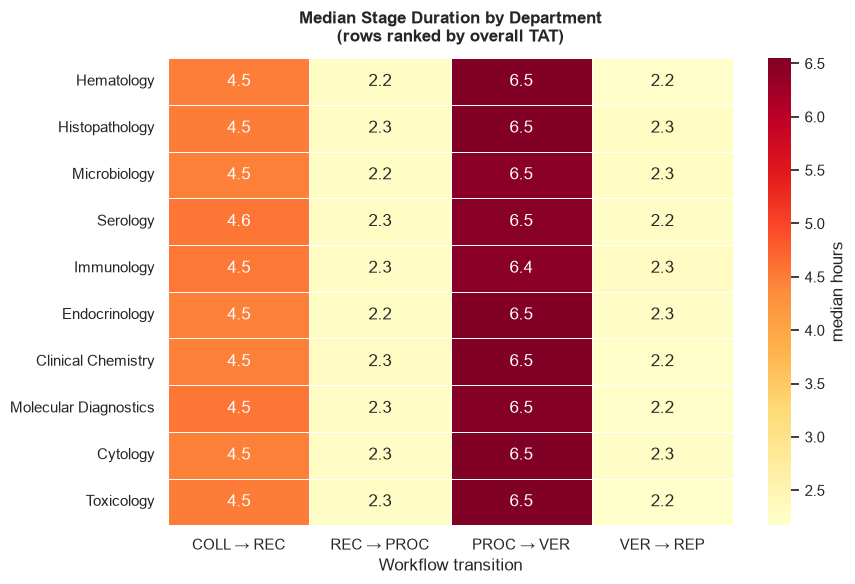

In [16]:
# Figure 3 - Department x stage heatmap (median hours)
heat = ranked[layer_cols].rename(columns=SHORT_LABELS)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    heat, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.6,
    cbar_kws={"label": "median hours"},
)
ax.set_title("Median Stage Duration by Department\n(rows ranked by overall TAT)",
             fontweight="bold", pad=12)
ax.set_xlabel("Workflow transition")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

### 9.4 Key findings — read-out of the stage analysis

In [17]:
dept_overall = dept_stage_table["overall_tat_h"]
slowest_dept, fastest_dept = dept_overall.idxmax(), dept_overall.idxmin()

print("Overall (all departments):")
print(f"  - Main TAT contributor   : {TRANSITION_LABELS[dominant]} ({shares[dominant]:.1%} of mean overall TAT)")
print(f"  - Longest single stage   : {overall_stage_summary['median_h'].idxmax()} "
      f"({overall_stage_summary['median_h'].max():.1f} h median)")

print("\nDepartments:")
print(f"  - Longest overall TAT    : {slowest_dept} ({dept_overall[slowest_dept]:.1f} h median)")
print(f"  - Fastest overall TAT    : {fastest_dept} ({dept_overall[fastest_dept]:.1f} h median) "
      f"-> slowest is {dept_overall[slowest_dept] / dept_overall[fastest_dept]:.1f}x slower")

print("\nDominant bottleneck stage, across departments:")
display(ranked["largest_delay_stage"].value_counts().rename_axis("stage").to_frame("departments"))

Overall (all departments):
  - Main TAT contributor   : Processing → Verified (42.0% of mean overall TAT)
  - Longest single stage   : Processing → Verified (6.5 h median)

Departments:
  - Longest overall TAT    : Hematology (15.6 h median)
  - Fastest overall TAT    : Toxicology (15.4 h median) -> slowest is 1.0x slower

Dominant bottleneck stage, across departments:


,departments
stage,
Processing → Verified,10


**Takeaways of §9.** The department × stage table (§9.2) and the three views (§9.3)
answer the questions directly: `overall_tat_h` ranks departments end-to-end,
`largest_delay_stage` names each department's bottleneck, and the stacked composition shows
how much of the total each stage owns everywhere. Table and figures share one ranking, so
the story stays consistent across views.

## 10. Sample Processing Performance — volumes, reporting and rejection

**Purpose.** Analyse the sample workflow and status: how far samples progress through
`collected → received → processing → verified → reported`, where they drop out, and what
characterises **rejections**.

**Questions answered**

1. How many **samples** and **tests** are in each state: received / processing / verified / reported / rejected?
2. What percentage of samples reach *reported*?
3. What percentage are rejected?
4. Which **departments** have the highest rejection rate?
5. Which **tests** have the highest rejection rate?
6. Which **sample types** have the highest rejection rate?
7. Are rejections concentrated on particular **days or hours**?
8. Is rejection associated with **longer TAT**?

**Reuse note:** everything is derived from the frames already built in §6–§9
(`stage_analysis_df` carries sample-level workflow timestamps, TAT and attributes;
`item_df` carries test-level detail). The raw event log `sample_state_df` is only touched
again for the *rejection-event* timestamp, which §6's pivot intentionally keeps out of the
completed-workflow frame.

### 10.1 Workflow status volumes — samples and tests

Answers: *how many samples/tests are received, processing, verified, reported, rejected?*

`stage_analysis_df` is one row per sample, so sample counts are plain non-null counts.
**Tests** inherit their sample's furthest state (a test cannot overtake its sample), so
test counts are the row counts of `item_df` joined on `sample_id`. The requested bar chart
shows the sample funnel in workflow order, with `rejected` beside it (an exit, not a stage).

In [18]:
def build_status_funnel(sample_df: pd.DataFrame, item_df: pd.DataFrame) -> pd.DataFrame:
    """Volumes per workflow state, for samples and for the tests riding on them."""
    STAGES = ["collected", "received", "processing", "verified", "reported"]
    stages = {f"{stage}_at": stage for stage in STAGES}

    funnel = pd.DataFrame({
        "state":     ["Collected", "Received", "Processing", "Verified", "Reported", "Rejected"],
        "samples": [int(sample_df[col].notna().sum()) for col in stages]
                  + [int(sample_df["is_rejected"].sum())],
    })
    furthest = sample_df[list(stages)].notna().sum(axis=1)  # stages a sample completed
    item_states = item_df.join(furthest.rename("stages_done"), on="sample_id")
    tests_per_stage = {
        "Collected": int((item_states["stages_done"] >= 1).sum()),
        "Received": int((item_states["stages_done"] >= 2).sum()),
        "Processing": int((item_states["stages_done"] >= 3).sum()),
        "Verified": int((item_states["stages_done"] >= 4).sum()),
        "Reported": int((item_states["stages_done"] >= 5).sum()),
        "Rejected": int(item_states["is_rejected"].sum()),
    }
    funnel["tests"] = funnel["state"].map(tests_per_stage)
    return funnel.set_index("state")


status_funnel = build_status_funnel(stage_analysis_df, item_df)
status_funnel["sample_share_pct"] = status_funnel["samples"] / len(stage_analysis_df)

display(status_funnel)

n = len(stage_analysis_df)
reported = int(stage_analysis_df["reported_at"].notna().sum())
rejected = int(stage_analysis_df["is_rejected"].sum())
print("\nQ2/Q3 — headline rates (of all samples):")
print(f"  - Reach reported : {reported:,} / {n:,} = {reported / n:.1%}")
print(f"  - Rejected       : {rejected:,} / {n:,} = {rejected / n:.2%}")
print(f"  - Still in process (no reported/rejected event): {n - reported:,} ({(n - reported) / n:.1%})")

,samples,tests,sample_share_pct
state,,,
Collected,49260,72945,1.00
Received,48873,72355,0.99
Processing,48873,72355,0.99
Verified,45655,67602,0.93
Reported,42510,63036,0.86
Rejected,387,591,0.01



Q2/Q3 — headline rates (of all samples):
  - Reach reported : 42,510 / 49,260 = 86.3%
  - Rejected       : 387 / 49,260 = 0.79%
  - Still in process (no reported/rejected event): 6,750 (13.7%)


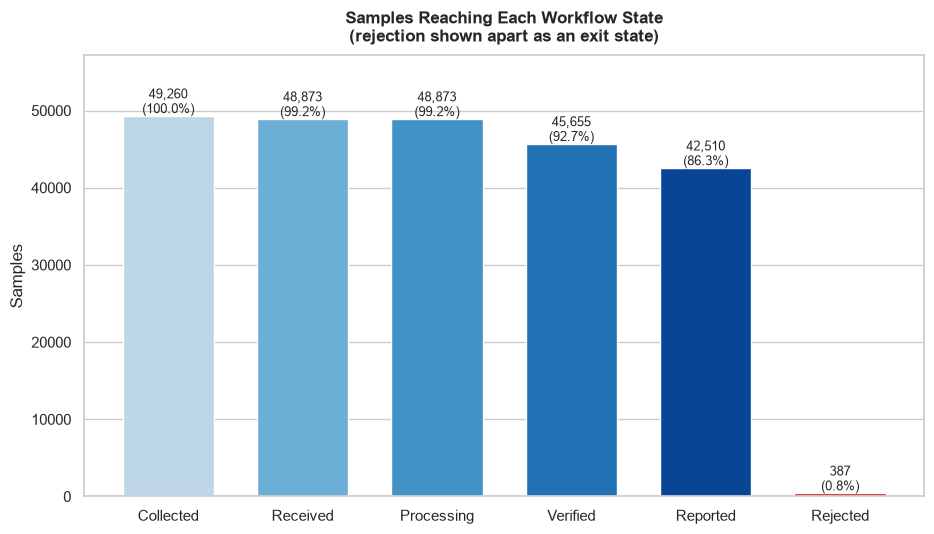

In [19]:
# Figure 4 - Volume of samples reaching each workflow state (requested bar chart)
colours = ["#bdd7e7", "#6baed6", "#4292c6", "#2171b5", "#084594", "#cb181d"]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.bar(status_funnel.index, status_funnel["samples"], color=colours,
              edgecolor="white", width=0.68)

for bar in bars:
    share = bar.get_height() / len(stage_analysis_df)
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 400,
            f"{int(bar.get_height()):,}\n({share:.1%})", ha="center", fontsize=9.5)

ax.set_ylabel("Samples")
ax.set_title("Samples Reaching Each Workflow State\n"
             "(rejection shown apart as an exit state)", fontweight="bold", pad=10)
ax.set_ylim(0, status_funnel["samples"].max() * 1.16)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### 10.2 Rejection profile — by department, test and sample type

Answers: *which departments, tests and sample types have the highest rejection rate?*

Rates are `rejected tests / all tests` on `item_analysis` (grain = order item, so a rate is
share of **test orders**, the denominator lab operations actually experience). All
rejections are sample-level — a rejected sample rejects every test on it — so the
department/test/type views agree by construction with the sample-level rate.

In [20]:
def rejection_table(df: pd.DataFrame, by: str, min_n: int = 1) -> pd.DataFrame:
    """Rejection rate (%) per group of `by', sorted descending, most-rejecting first."""
    out = (
        df.groupby(by)
        .agg(samples_or_tests=("order_item_id", "size"), rejections=("is_rejected", "sum"),
             rejection_rate_pct=("is_rejected", "mean"))
        .sort_values("rejection_rate_pct", ascending=False)
    )
    out["rejection_rate_pct"] = out["rejection_rate_pct"] * 100
    out["rejections"] = out["rejections"].astype(int)
    return out[out["samples_or_tests"] >= min_n]


print("Rejections by department (all 10):"); display(rejection_table(item_df, "department_name"))
print("\nTop 10 tests by rejection rate (test orders as denominator):")
display(rejection_table(item_df, "test_name").head(10))
print("\nRejections by sample type:"); display(rejection_table(item_df, "sample_type").head(6))

print("\nOverall: "
      f"{item_df['is_rejected'].sum():,} rejected test orders on "
      f"{stage_analysis_df['is_rejected'].sum():,} rejected samples "
      f"(a rejected sample takes all of its tests with it).")

Rejections by department (all 10):


,samples_or_tests,rejections,rejection_rate_pct
department_name,,,
Serology,11558,113,0.98
Immunology,7365,68,0.92
Histopathology,4350,40,0.92
Molecular Diagnostics,7292,64,0.88
Clinical Chemistry,8732,69,0.79
Toxicology,9062,71,0.78
Endocrinology,8827,68,0.77
Cytology,3360,22,0.65
Microbiology,4918,32,0.65



Top 10 tests by rejection rate (test orders as denominator):


,samples_or_tests,rejections,rejection_rate_pct
test_name,,,
Anti-HBc Total,151,6,3.97
Streptococcus agalactiae (GBS) PCR,147,5,3.40
Amikacin Peak Level,149,5,3.36
Pneumococcal Urinary Antigen,160,5,3.12
Beta-2 Glycoprotein I IgG,165,5,3.03
HSV-1 IgG,141,4,2.84
Cryptococcus neoformans PCR,142,4,2.82
VDRL (Venereal Disease Research Lab),143,4,2.80
P-ANCA (Quantitative),146,4,2.74



Rejections by sample type:


,samples_or_tests,rejections,rejection_rate_pct
sample_type,,,
semen,306,3,0.98
serum,33719,298,0.88
pleural fluid,9279,78,0.84
stool,1987,16,0.81
blood,20704,154,0.74
urine,2462,18,0.73



Overall: 591 rejected test orders on 387 rejected samples (a rejected sample takes all of its tests with it).


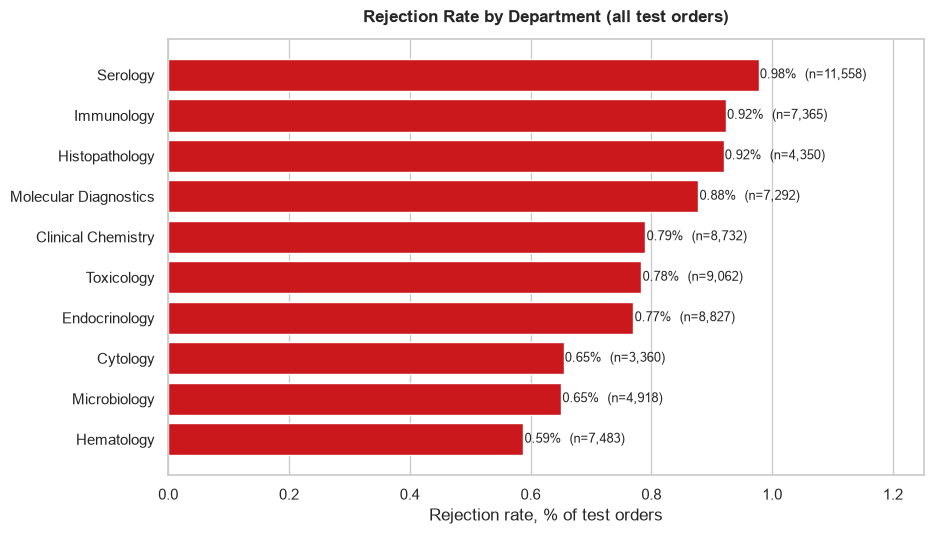

In [21]:
# Figure 5 - Rejection rate by department with volume context
rej_dept = rejection_table(item_df, "department_name")

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.barh(rej_dept.index, rej_dept["rejection_rate_pct"], color="#cb181d", edgecolor="white")
ax.invert_yaxis()

for bar, row in zip(bars, rej_dept.itertuples()):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}%  (n={int(row.samples_or_tests):,})",
            va="center", fontsize=9)

ax.set_xlabel("Rejection rate, % of test orders")
ax.set_title("Rejection Rate by Department (all test orders)", fontweight="bold", pad=12)
ax.set_xlim(0, rej_dept["rejection_rate_pct"].max() * 1.28)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

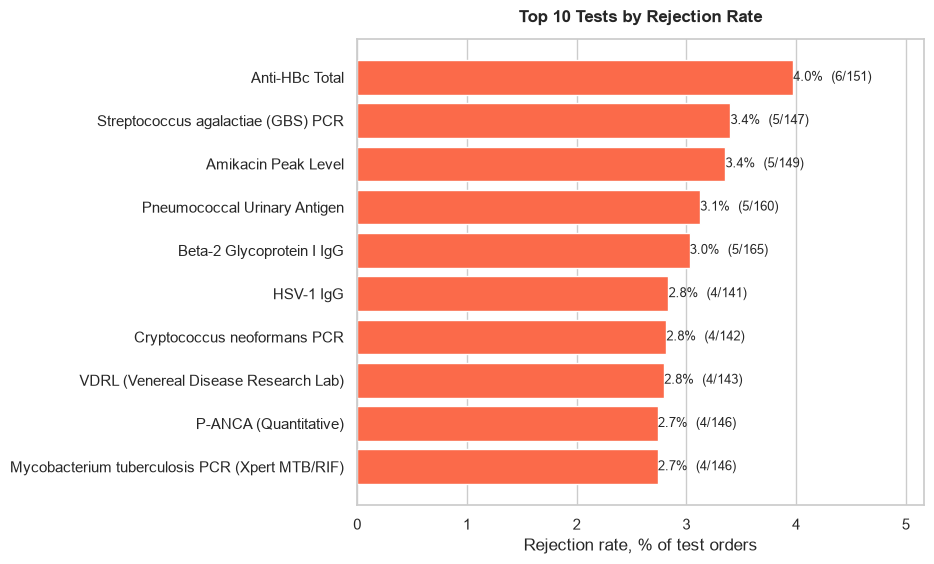

Rejection rate by sample type:


,samples_or_tests,rejections,rejection_rate_pct
sample_type,,,
semen,306,3,0.98
serum,33719,298,0.88
pleural fluid,9279,78,0.84
stool,1987,16,0.81
blood,20704,154,0.74
urine,2462,18,0.73
csf,842,6,0.71
plasma,2756,14,0.51
sputum,892,4,0.45


In [22]:
# Figure 6 - Top 10 tests by rejection rate (with volumes)
rej_test = rejection_table(item_df, "test_name").head(10)

fig, ax = plt.subplots(figsize=(9.5, 5.8))
bars = ax.barh(rej_test.index, rej_test["rejection_rate_pct"], color="#fb6a4a", edgecolor="white")
ax.invert_yaxis()

for bar, row in zip(bars, rej_test.itertuples()):
    ax.text(bar.get_width() + 0.0008, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%  ({int(row.rejections)}/{int(row.samples_or_tests)})",
            va="center", fontsize=9)

ax.set_xlabel("Rejection rate, % of test orders")
ax.set_title("Top 10 Tests by Rejection Rate", fontweight="bold", pad=12)
ax.set_xlim(0, rej_test["rejection_rate_pct"].max() * 1.3)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

rej_type = rejection_table(item_df, "sample_type")
print("Rejection rate by sample type:")
display(rej_type.round(2))

### 10.3 When do rejections happen — day of week and hour of day?

Answers: *are rejected samples concentrated on particular days or hours?*

The timing anchor is the **rejection-event timestamp** from the state log (when the
rejection was recorded), compared against the **day/hour profile of all collected samples**.
Rates — not raw counts — are shown, so a busy Monday does not masquerade as a
rejection-prone Monday.

In [23]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def rejection_timing_columns() -> pd.DataFrame:
    """Add weekday / hour-of-day anchors: rejection moment for rejected samples,
    collection moment for the whole population (the exposure baseline)."""
    events = sample_state_df.loc[sample_state_df["state"] == "rejected", ["sample_id", "timestamp"]]
    rej_moment = pd.to_datetime(events["timestamp"], utc=True)

    collected_moment = stage_analysis_df.set_index("sample_id")["collected_at"]
    return rej_moment, collected_moment


rejection_at, collected_at = rejection_timing_columns()

rej_week, rej_hour = rejection_at.dt.dayofweek, rejection_at.dt.hour
all_week, all_hour = collected_at.dt.dayofweek, collected_at.dt.hour

by_weekday = pd.DataFrame({
    "collected": all_week.value_counts().reindex(range(7)).fillna(0),
    "rejections": rej_week.value_counts().reindex(range(7)).fillna(0),
})
by_weekday["rejection_rate_pct"] = by_weekday["rejections"] / by_weekday["collected"] * 100
by_weekday.index = WEEKDAYS

by_hour = pd.DataFrame({
    "collected": all_hour.value_counts().reindex(range(24)).fillna(0),
    "rejections": rej_hour.value_counts().reindex(range(24)).fillna(0),
})
by_hour["rejection_rate_pct"] = by_hour["rejections"] / by_hour["collected"] * 100

print("Rejections by weekday:")
display(by_weekday.round(2))
print(f"Weekend share of rejections: {(rej_week >= 5).mean():.1%} "
      f"(weekend share of collections: {(all_week >= 5).mean():.1%})")

Rejections by weekday:


,collected,rejections,rejection_rate_pct
Mon,6661,44,0.66
Tue,6482,60,0.93
Wed,6773,53,0.78
Thu,10109,79,0.78
Fri,6355,53,0.83
Sat,6441,53,0.82
Sun,6439,45,0.70


Weekend share of rejections: 25.3% (weekend share of collections: 26.1%)


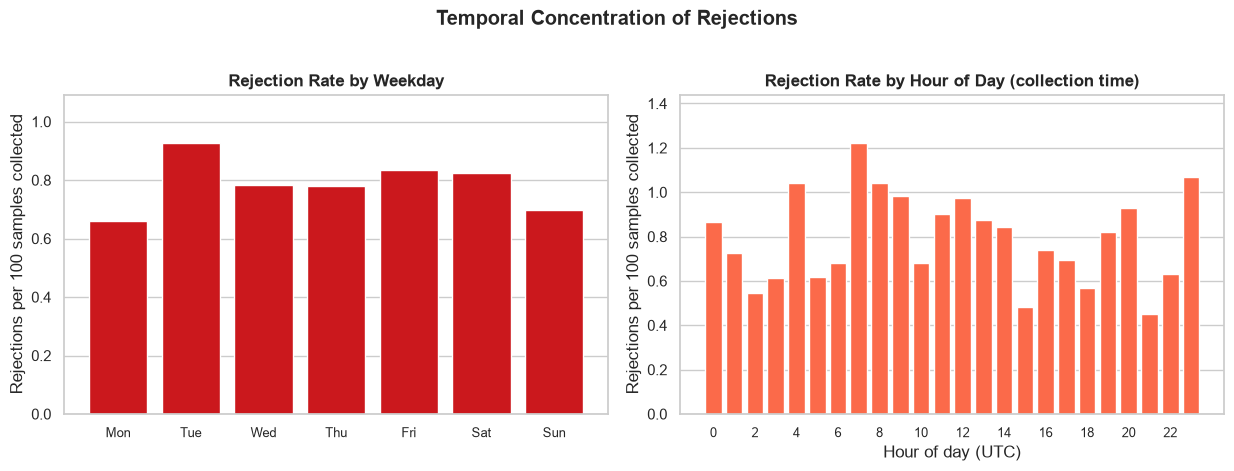

In [24]:
# Figure 7 - Are rejections concentrated in time? Rejection rate by weekday and hour
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

axes[0].bar(by_weekday.index, by_weekday["rejection_rate_pct"], color="#cb181d", edgecolor="white")
axes[0].set_title("Rejection Rate by Weekday", fontweight="bold")
axes[0].set_ylabel("Rejections per 100 samples collected")
axes[0].grid(axis="x", visible=False)

hourly_axis = axes[1].bar(by_hour.index, by_hour["rejection_rate_pct"], color="#fb6a4a", edgecolor="white")
axes[1].set_title("Rejection Rate by Hour of Day (collection time)", fontweight="bold")
axes[1].set_xlabel("Hour of day (UTC)")
axes[1].set_ylabel("Rejections per 100 samples collected")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(axis="x", visible=False)

for axx in axes:
    axx.tick_params(axis="x", labelsize=9)
    axx.margins(y=0.18)

fig.suptitle("Temporal Concentration of Rejections", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

### 10.4 Is rejection associated with longer TAT?

Answers: *do rejected samples differ in turnaround behaviour?*

**Structural fact first:** rejection and *reported* are mutually exclusive states — a
rejected sample never reaches final report, so **end-to-end TAT (§7 definition) does not
exist for rejected samples**. The association is therefore read on the shared interval all
samples do have — *collection → received* (pre-analytical logistics) — plus how much
lifetime a rejected sample burns before being written off (`collection → rejection
moment`).

In [25]:
# Q8: rejection x turnaround behaviour
rej_sample_ids = set(stage_analysis_df.loc[stage_analysis_df["is_rejected"], "sample_id"])

comparison = (
    stage_analysis_df.assign(was_rejected=stage_analysis_df["is_rejected"])
    .groupby("was_rejected")
    .agg(samples=("sample_id", "size"),
         collected_to_received_h=("pre_analytical_tat_h", "median"))
)

# Extra clock a rejected sample runs before write-off (collected -> rejection moment).
rejected_profile = stage_analysis_df.loc[
    stage_analysis_df["is_rejected"], ["sample_id", "collected_at"]
].copy()
rejected_profile["rejection_at"] = pd.to_datetime(
    sample_state_df.loc[sample_state_df["state"] == "rejected"]
    .set_index("sample_id")["timestamp"],
    utc=True,
).reindex(rejected_profile["sample_id"]).to_numpy()
liftetime = None  # (name reserved below)
lifetime = (
    rejected_profile["rejection_at"] - rejected_profile["collected_at"]
).dt.total_seconds() / 3600

display(comparison.round(2))
print(f"\n- Rejected samples never reach 'verified'/'reported' -> overall TAT undefined for them"
      f"\n  (structurally excluded from the 86.3% reporting rate seen in Q2).")
print(f"- Median pre-analytical interval (collection -> reception):")
for flag, med in comparison["collected_to_received_h"].items():
    print(f"    {'rejected' if flag else 'not rejected':<12} {med:.2f} h")
print(f"\n- Median time a sample stays in limbo before its rejection is logged: "
      f"{lifetime.median():.2f} h after collection.")

,samples,collected_to_received_h
was_rejected,,
False,48873,4.51
True,387,NaN



- Rejected samples never reach 'verified'/'reported' -> overall TAT undefined for them
  (structurally excluded from the 86.3% reporting rate seen in Q2).
- Median pre-analytical interval (collection -> reception):
    not rejected 4.51 h
    rejected     nan h

- Median time a sample stays in limbo before its rejection is logged: 3.51 h after collection.


**Takeaways of §10.** The funnel (§10.1) quantifies both attrition between stages and
the rejection exit; the rejection profile (§10.2) ranks departments, tests and sample types
by their share of test orders rejected; the timing view (§10.3) tests weekday/hour
concentration with rates rather than raw counts; and §10.4 establishes that rejection sits
*outside* the TAT population (structural mutual exclusion), shifting the improvement
conversation to prevention at collection rather than faster processing of rejected
work.

## Notes and next steps

- **Definitions**: `tat_total_h` (primary) = sample *collection* → *final report*; stage
  TATs cover the pre-analytical, analytical and post-analytical phases. All values in
  **hours**, timestamps in **UTC**.
- **Scope**: TAT is computed at *sample* level; per-test and per-parameter views can be
  derived by joining `tat_analysis_df` to `item_analysis` / `report_analysis` on `sample_id`
  / `order_item_id`.
- **Data hygiene**: no source dataset was modified; datetime normalisation happened in
  memory only and existing UTC dtypes were preserved.
- **Natural next steps**: TAT distributions by department/test, SLA breach drivers
  (priority × department × hour-of-day), weekend vs weekday effect, and rejection-rate
  impact on turnaround.